In [ ]:
%load_ext autoreload
%autoreload 2
import os

os.chdir('/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC')
from reproject.mosaicking import find_optimal_celestial_wcs, reproject_and_coadd

import numpy as np; import pandas as pd
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from astropy.io import fits, ascii; from astropy.stats import knuth_bin_width; from astropy.table import Table

import scripts.phot_toolkit as PTK; import scripts.photometric_pipeline as PPL; 

working_directory = "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST"
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory = working_directory)


**WARNING**: LOCAL JWST PRD VERSION PRDOPSSOC-073 DOESN'T MATCH THE CURRENT ONLINE VERSION PRDOPSSOC-075
Please consider updating pysiaf, e.g. pip install --upgrade pysiaf or conda update pysiaf


The current archive release 3.15 contains two breaking changes. Please see https://www.cosmos.esa.int/web/gaia/news#GACSrelease315 for details. In case of questions or feedback, please consult the Gaia helpdesk at https://www.cosmos.esa.int/web/gaia/gaia-helpdesk.
The following task in the stsci.skypac package can be run with TEAL:
                                    skymatch                                    
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


Running for F115W...
    (3) Running starbug
Skipping starbug2 run
--- Running stargbug finalized ---
[0 1]
Plotting Level 2 downloaded data...
/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC


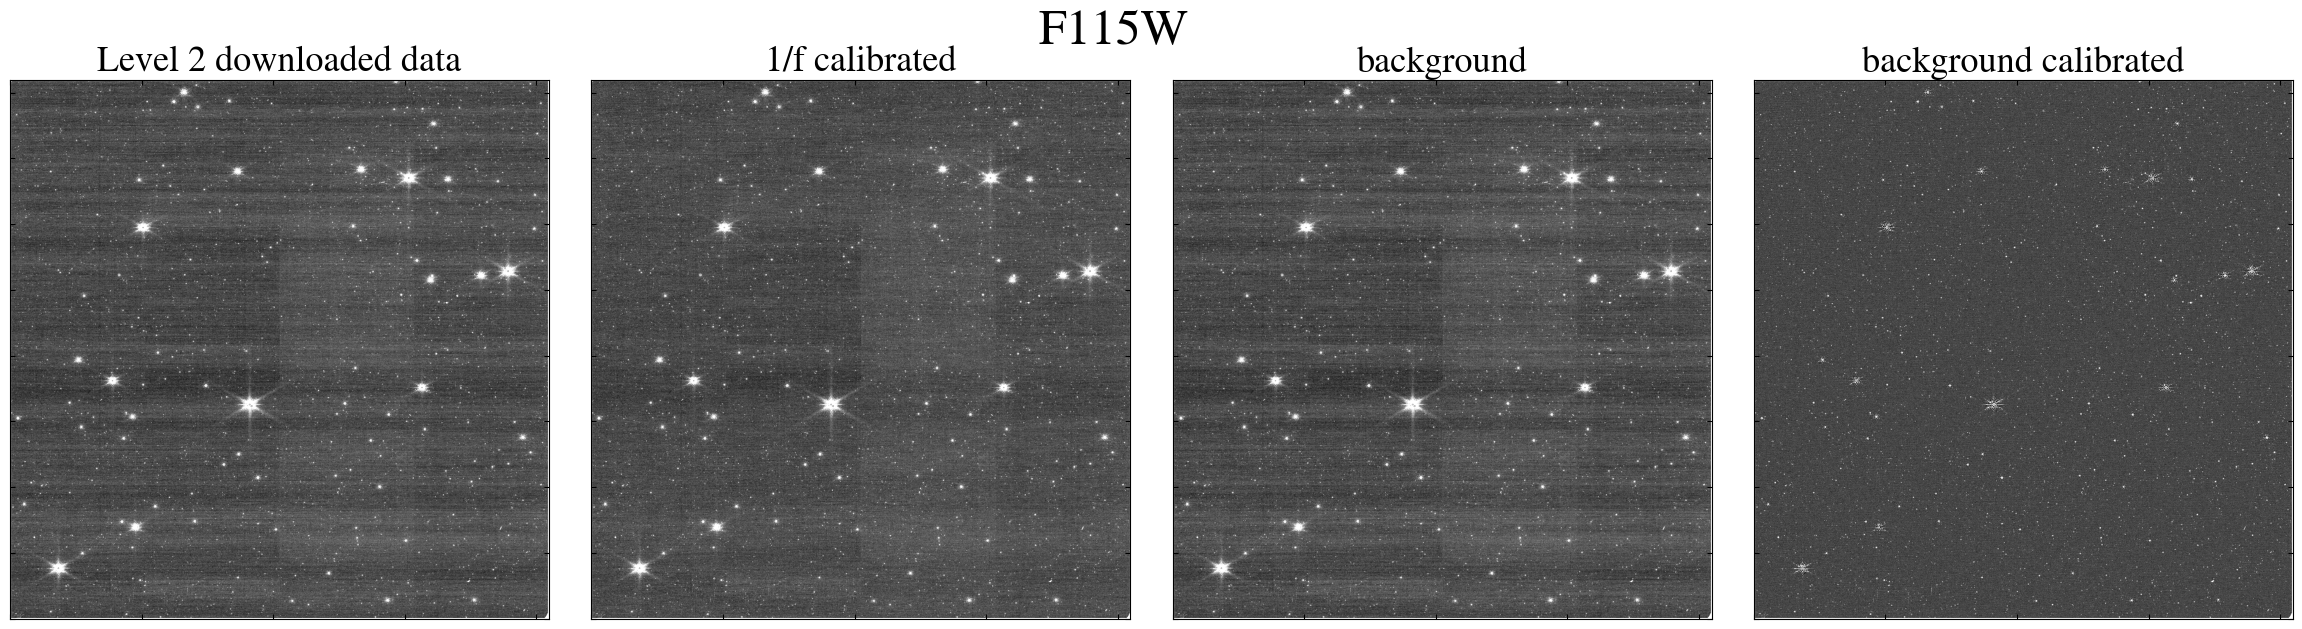

----Pipeline-----
JWST pipeline version             : 2.0.1
Calibration Reference Data System : 13.1.13
CRDS context map                  : jwst_1535.pmap
Read-out pattern                  : BRIGHT2
Number of read-out groups         : 2
----Completed----


In [ ]:
IMAGE_INDEX = 89

PHOTOMETRIC_pipeline.run_pipeline_single( IMAGE_INDEX           = IMAGE_INDEX,
                                            detection_sigma     = 2.0,
                                            overwrite_always_run= False,
                                            save                = True,
                                            known_sources       = True)


In [14]:
from astropy.visualization import ZScaleInterval

from matplotlib.collections import EllipseCollection
from astropy.wcs import WCS
from reproject import reproject_interp
import matplotlib.patches as mpatches

def _draw_markers(ax, x, y, r, color):
    """Detections; points are dropped if not in frame"""

    ax.add_collection(
            EllipseCollection(
                2 * r,
                2 * r,
                0,
                units="xy",
                offsets=np.c_[x, y],
                offset_transform=ax.transData,  # transOffset= on matplotlib < 3.6
                fc="none",
                ec=color,
                lw=1))

    return 

def find_center(ny, nx, wcs ):
    return wcs.pixel_to_world((nx - 1) / 2, (ny - 1) / 2)

def plot_test(  Image_path  = JWST_files.files.file_paths_1overf_jhat['F115W'][IMAGE_INDEX],
                dra         = 1 * u.arcmin, 
                ddec        = 0 * u.arcmin,
                rot         = 0 * u.deg,                    
                width       = 2 * u.arcmin,                
                height      = 2 * u.arcmin,
                pix_scale   = 0.5 * u.arcsec,   
                source_coordinates = SkyCoord(ra=0*u.deg, dec=0*u.deg,frame='icrs'),
                save_name= 'Plots/XXX.pdf',
                tag = None,
                ):

    with fits.open(Image_path, memmap=True) as hdu:
        data    = hdu['SCI'].data
        wcs    = WCS(hdu['SCI'].header, hdu)
        center = find_center(*data.shape, wcs= wcs)
        target_wcs, shape_out = phot_tk.make_target_wcs(center, dra, ddec, rot, width, height, pix_scale)
        
        img, _ = reproject_interp((data, wcs), target_wcs, shape_out=shape_out)


    fig = plt.figure(figsize=(5,5))
    gs = gridspec.GridSpec(1, 1, figure=fig)  # once, before the loop
    ax = fig.add_subplot(gs[0, 0], projection=target_wcs)

    interval            = ZScaleInterval()
    vmin, vmax          = interval.get_limits(img)

    cmap = 'gray'
    ax.imshow(img, cmap=cmap, vmin=vmin, vmax=vmax, origin='lower')

    mask = phot_tk.in_wcs_mask(source_coordinates.ra, source_coordinates.dec, target_wcs, shape_out)
    x, y = target_wcs.world_to_pixel(source_coordinates[mask])    
    n_y, n_x = shape_out

    _draw_markers(ax, x, y, r=2, color= "#ff004c")
    
    x, y = target_wcs.world_to_pixel(source_coordinates[mask&tag])  
    _draw_markers(ax, x, y, r=2, color= "#22FF47")

    ax.set_facecolor(plt.colormaps[cmap](0))
    ax.coords['ra'].set_axislabel('RA')
    ax.coords['dec'].set_axislabel('Dec')
    ax.grid(color='w', alpha=0.3)
    plt.savefig(save_name, bbox_inches='tight')
    return target_wcs, shape_out


In [15]:
RA_min, RA_max      = JWST_files.aperture_data['F115W'].RA.min(), JWST_files.aperture_data['F115W'].RA.max()
DEC_min, DEC_max    = JWST_files.aperture_data['F115W'].DEC.min(), JWST_files.aperture_data['F115W'].DEC.max()
region              = np.array([[RA_min, RA_max], [DEC_min, DEC_max] ])
center              = SkyCoord(ra=np.mean(region[0])*u.deg, dec=np.mean(region[1])*u.deg,frame='icrs')


In [16]:


catalogue_path  = 'Photometry/NGC346_NIRCam_and_MIRI_Public_JWST_Catalogue.fits'
Catalogue       = phot_tk.Read_Catalogue(catalogue_path = catalogue_path)
outfile         = Catalogue.make_source_list(filt_mask_on = ('F115W', 2.0),  outfile = 'Photometry/test_pos.fits')
Catalogue       = Table.read(outfile, hdu=1)
specific_ra_dec = SkyCoord(ra=Catalogue['RA'], dec=Catalogue['DEC'],frame='icrs')


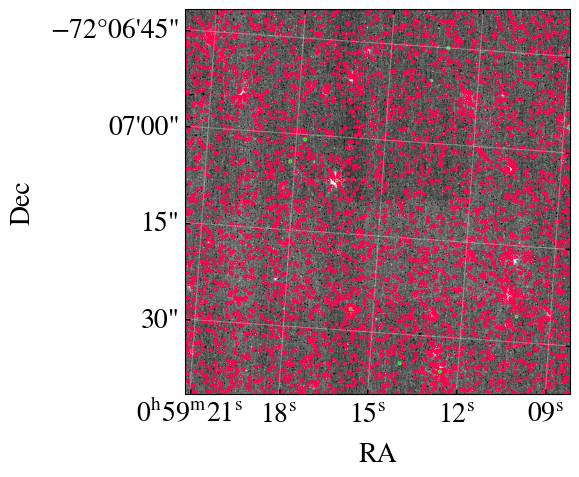

In [17]:
target_wcs, shape_out = plot_test(JWST_files.files.file_paths_1overf_jhat['F115W'][IMAGE_INDEX],
            # dra         = -0.35 * u.arcmin, 
            # ddec        = -0.225 * u.arcmin,
            # rot         = 4 * u.deg,                    
            # width       = 0.3 * u.arcmin,                
            # height      = 0.3 * u.arcmin,
            # pix_scale   = 0.1 * u.arcsec,   
            dra         = 0 * u.arcmin, 
            ddec        = 0 * u.arcmin,
            rot         = 4 * u.deg,                    
            width       = 1 * u.arcmin,                
            height      = 1 * u.arcmin,
            pix_scale   = 0.1 * u.arcsec,           
            source_coordinates = specific_ra_dec,
            #source_coordinates = SkyCoord(ra=0*u.deg, dec=0*u.deg,frame='icrs'),
            tag         = Catalogue['Pa-alpha_excess'] == 'Y',
            save_name   = 'Plots/Source_jeroen_no_detect_long.pdf'
            )

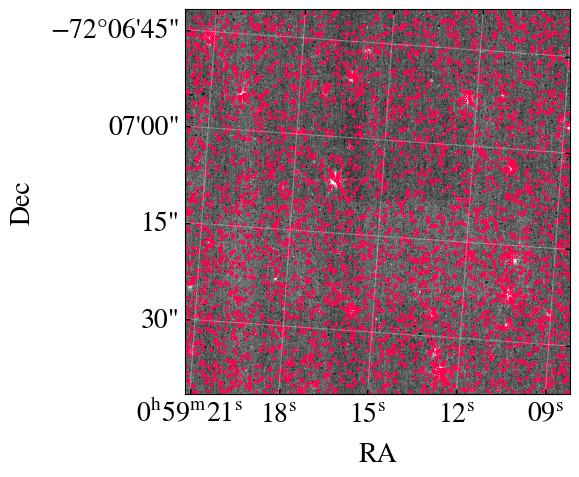

In [18]:


specific_ra_dec     = SkyCoord(ra=JWST_files.world_coord_sources['F115W'][0] *u.deg, 
                               dec=JWST_files.world_coord_sources['F115W'][1]*u.deg, 
                               frame='icrs')
target_wcs, shape_out = plot_test(JWST_files.files.file_paths_1overf_jhat['F115W'][IMAGE_INDEX],
            dra         = 0 * u.arcmin, 
            ddec        = 0 * u.arcmin,
            rot         = 4 * u.deg,                    
            width       = 1 * u.arcmin,                
            height      = 1 * u.arcmin,
            pix_scale   = 0.1 * u.arcsec,             
            source_coordinates = specific_ra_dec,
            save_name   = 'Plots/Source_SB2_long.pdf',
            tag         = False
            )

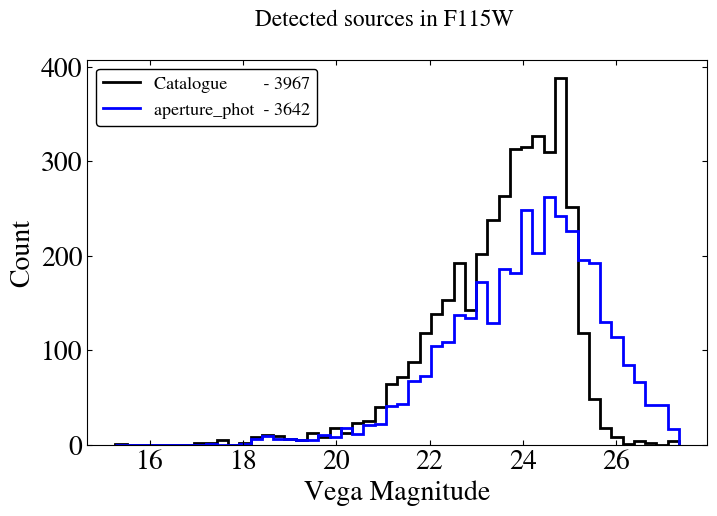

In [20]:
fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])

mask = phot_tk.in_wcs_mask(Catalogue['RA'], Catalogue['DEC'], target_wcs, shape_out)
samples = Catalogue['F115W'][mask]
N_samples = len(samples)
dx, bin_edges = knuth_bin_width(samples, return_bins=True)
hist = np.histogram(samples, bins=bin_edges)[0]
ax0.stairs(
    hist,
    edges=bin_edges, fill=False, label=f'Catalogue        - {N_samples}', lw=2, edgecolor='black'
    )

                               
mask = phot_tk.in_wcs_mask(JWST_files.world_coord_sources['F115W'][0] *u.deg, JWST_files.world_coord_sources['F115W'][1] *u.deg, target_wcs, shape_out)

own_phot = JWST_files.magnitudes['F115W'][mask]
N_own_phot = len(own_phot)
own_hist = np.histogram(own_phot, bins=bin_edges)[0]
ax0.stairs(
    own_hist,
    edges=bin_edges, fill=False, label=f'aperture_phot  - {N_own_phot}', lw=2, edgecolor='blue'
    )
    

ax0.legend()
ax0.set_xlabel("Vega Magnitude")
ax0.set_ylabel("Count")
# ax0.set_ylim(0, 500)
fig.suptitle(f"Detected sources in F115W ")
plt.show()

1


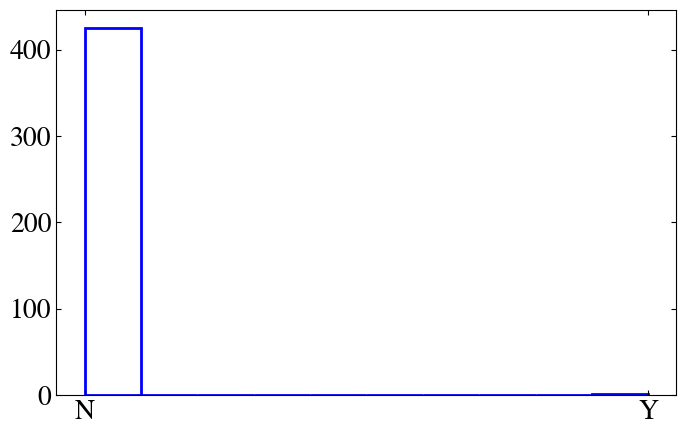

In [171]:
mask = phot_tk.in_wcs_mask(Catalogue['RA'], Catalogue['DEC'], target_wcs, shape_out)
samples = Catalogue['Pa-alpha_excess'][mask]
print(np.sum(samples == 'Y'))

plt.figure()
plt.hist(samples, fill=False, lw=2, edgecolor='blue')

plt.show()